In [1]:
import sys
from pathlib import Path

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, features

import numpy as np
import pandas as pd
import keras
import matplotlib.pyplot as plt

I0000 00:00:1795620162.242135   12063 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# === Chargement du modèle entrainé === #
Fitted_Model = keras.models.load_model(RACINE / "Sources" / "Fitted_models" / "DAE_fitted.keras")

In [3]:
def construire_fenetres_brutes_test(nom, canal="DE", duree=0.17067, recouvrement=0.5, signaux=None):
    """Fenêtres brutes d'un canal d'un fichier.
    `signaux` = sortie de data.charger() si le fichier est déjà chargé (évite de relire le .mat)."""
    if signaux is None:
        signaux = data.charger(nom, canaux=(canal,))
    fenetres = features.fenetrer(signaux[canal], signaux["fs"], duree=duree, recouvrement=recouvrement)
    return np.array(fenetres, dtype=np.float32)

def score_mse(modele, X):
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

def Tester_signal(modele, input, seuil):
    score = score_mse(modele, input)
    Nb_Defaut = (score > seuil).sum()
    Nb_Sain = (score < seuil).sum()
    print(f"Pourcentage de chance d'être un défaut : {Nb_Defaut/(Nb_Sain+Nb_Defaut)*100:.2f}%")
    plt.plot(score, label="Signal testé")
    plt.axhline(seuil, color="black", ls="--", lw=1, label="seuil d'alarme")
    plt.title("Score d'anomalie au cours du temps")
    plt.xlabel("fenêtre du signal"); plt.ylabel("MSE de reconstruction")
    plt.legend(); plt.show()

def tester_fichier(modele, nom, seuil, taille, canaux=("DE", "FE"),
                   duree=0.17067, recouvrement=0.5, tracer=True):
    """Teste UN fichier sur tous les canaux disponibles (DE, FE).
    Renvoie un DataFrame : une ligne par canal avec le score d'erreur
    (MSE moyenne/médiane/max, % de fenêtres > seuil, defaut_detecte).
    Conclusion : le canal avec la MSE moyenne la plus grande porte le défaut."""
    signaux = data.charger(nom, canaux=canaux)          # charge tous les canaux en une seule fois
    lignes, scores = [], {}
    for canal in canaux:
        if signaux.get(canal) is None:                  # canal absent du .mat
            print(f"  canal {canal} indisponible pour {nom}")
            continue
        X = construire_fenetres_brutes_test(nom, canal=canal, duree=duree,
                                            recouvrement=recouvrement, signaux=signaux)
        assert X.shape[1] == taille, \
            f"fenêtres de {X.shape[1]} éch., modèle entraîné sur {taille} (vérifier duree et fs)"
        Xn = features.standardiser_par_fenetre(X)       # option A : sans état, identique train/test
        s = score_mse(modele, Xn)
        scores[canal] = s
        lignes.append({
            "fichier": nom, "canal": canal, "n_fenetres": len(s),
            "MSE_moyenne": s.mean(), "MSE_mediane": np.median(s), "MSE_max": s.max(),
            "%_fenetres_>_seuil": 100 * (s > seuil).mean(),
            "defaut_detecte": bool((s > seuil).any()),
        })
    df = pd.DataFrame(lignes)
    if len(df):
        i_max = df["MSE_moyenne"].idxmax()
        df.attrs["canal_defaut"] = df.loc[i_max, "canal"]
        print(f"{nom} -> canal avec la MSE la plus forte : {df.loc[i_max, 'canal']} "
              f"(MSE moy = {df.loc[i_max, 'MSE_moyenne']:.4f})")
    if tracer and scores:
        plt.figure(figsize=(10, 4))
        for canal, s in scores.items():
            plt.plot(s, label=f"canal {canal}")
        plt.axhline(seuil, color="black", ls="--", lw=1, label="seuil d'alarme")
        plt.title(f"Score d'anomalie (MSE) par canal — {nom}")
        plt.xlabel("fenêtre du signal"); plt.ylabel("MSE de reconstruction")
        plt.legend(); plt.show()
    return df

def tester_plusieurs_fichiers(modele, noms, seuil, taille, canaux=("DE", "FE"), tracer=False):
    """Teste une liste de fichiers -> (résumé, détails canal par canal).
    'defaut_attendu' lu dans le nom : 12kDE_* -> DE, 12kFE_* -> FE, Normal_* -> Sain.
    'localisation_ok' vérifie que le canal à la MSE max est bien le capteur attendu."""
    details, resume = [], []
    for nom in noms:
        df = tester_fichier(modele, nom, seuil, taille, canaux=canaux, tracer=tracer)
        details.append(df)
        attendu = "FE" if "FE" in nom else ("DE" if "DE" in nom else "Sain")
        canal_detecte = df.attrs.get("canal_defaut")
        resume.append({
            "fichier": nom,
            "defaut_attendu_sur": attendu,
            "canal_MSE_max_detecte": canal_detecte,
            "MSE_moyenne_max": df["MSE_moyenne"].max(),
            "%_fen_max_>_seuil": df["%_fenetres_>_seuil"].max(),
            "defaut_detecte_qcq": bool(df["defaut_detecte"].any()),
            "localisation_ok": (attendu == "Sain" and not df["defaut_detecte"].any())
                               or (attendu != "Sain" and canal_detecte == attendu),
        })
    return pd.DataFrame(resume), pd.concat(details, ignore_index=True)

In [4]:
import joblib
pack = joblib.load(RACINE / "Sources" / "Fitted_models" / "DAE_params.joblib")
seuil, taille = pack["seuil"], pack["taille_fenetre"]
print(f"seuil p99 = {seuil:.4f} | fenêtre = {taille} points (duree=0.17067 à 12 kHz)")

seuil p99 = 0.0096 | fenêtre = 2048 points (duree=0.17067 à 12 kHz)


12kDE_B007_L0 -> canal avec la MSE la plus forte : DE (MSE moy = 0.9408)


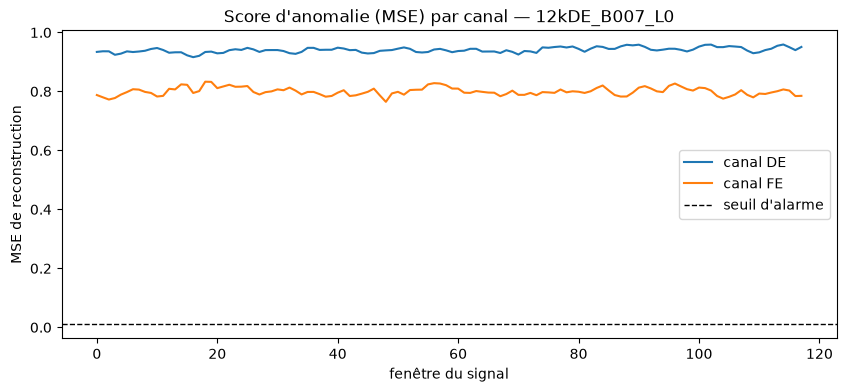

,fichier,canal,n_fenetres,MSE_moyenne,MSE_mediane,MSE_max,%_fenetres_>_seuil,defaut_detecte
0,12kDE_B007_L0,DE,118,0.940752,0.940334,0.959169,100.0,True
1,12kDE_B007_L0,FE,118,0.799969,0.798482,0.832996,100.0,True


Canal portant le défaut : DE (attendu : DE)
Normal_L0 -> canal avec la MSE la plus forte : FE (MSE moy = 0.0061)
12kDE_B007_L0 -> canal avec la MSE la plus forte : DE (MSE moy = 0.9408)
12kDE_IR007_L3 -> canal avec la MSE la plus forte : DE (MSE moy = 0.8697)
12kDE_B021_L1 -> canal avec la MSE la plus forte : DE (MSE moy = 0.9238)
12kFE_IR007_L0 -> canal avec la MSE la plus forte : FE (MSE moy = 0.7787)
12kFE_OR007at12_L0 -> canal avec la MSE la plus forte : FE (MSE moy = 0.6378)


,fichier,defaut_attendu_sur,canal_MSE_max_detecte,MSE_moyenne_max,%_fen_max_>_seuil,defaut_detecte_qcq,localisation_ok
0,Normal_L0,Sain,FE,0.006068,0.0,False,True
1,12kDE_B007_L0,DE,DE,0.940752,100.0,True,True
2,12kDE_IR007_L3,DE,DE,0.869730,100.0,True,True
3,12kDE_B021_L1,DE,DE,0.923831,100.0,True,True
4,12kFE_IR007_L0,FE,FE,0.778723,100.0,True,True
5,12kFE_OR007at12_L0,FE,FE,0.637830,100.0,True,True


,fichier,canal,n_fenetres,MSE_moyenne,MSE_mediane,MSE_max,%_fenetres_>_seuil,defaut_detecte
0,Normal_L0,DE,237,0.005136,0.005112,0.007181,0.0,False
1,Normal_L0,FE,237,0.006068,0.005933,0.007853,0.0,False
2,12kDE_B007_L0,DE,118,0.940752,0.940334,0.959169,100.0,True
3,12kDE_B007_L0,FE,118,0.799969,0.798482,0.832996,100.0,True
4,12kDE_IR007_L3,DE,119,0.869730,0.868392,0.888789,100.0,True
5,12kDE_IR007_L3,FE,119,0.428248,0.426953,0.452994,100.0,True
6,12kDE_B021_L1,DE,117,0.923831,0.917998,0.984878,100.0,True
7,12kDE_B021_L1,FE,117,0.698878,0.689812,0.875303,100.0,True
8,12kFE_IR007_L0,DE,117,0.731007,0.731245,0.788448,100.0,True
9,12kFE_IR007_L0,FE,117,0.778723,0.781122,0.839160,100.0,True


In [5]:
# 1 fichier en détail, DE vs FE : le défaut B007 est côté DE, on teste les deux capteurs
df_1fichier = tester_fichier(Fitted_Model, "12kDE_B007_L0", seuil, taille, canaux=("DE", "FE"))
display(df_1fichier)
print("Canal portant le défaut :", df_1fichier.attrs["canal_defaut"], "(attendu : DE)")

# Plusieurs fichiers : tableau récapitulatif + détails canal par canal
fichiers_test = ["Normal_L0", "12kDE_B007_L0", "12kDE_IR007_L3", "12kDE_B021_L1",
                 "12kFE_IR007_L0", "12kFE_OR007at12_L0"]
resume, details = tester_plusieurs_fichiers(Fitted_Model, fichiers_test, seuil, taille)
display(resume)
display(details)